In [109]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
import re
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import RobustScaler, OneHotEncoder

In [110]:
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/refs/heads/master/titanic.csv"
df = pd.read_csv(url)

In [111]:
df.head(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [112]:
df.shape

(891, 12)

In [113]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [114]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [115]:
df.isna().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


<Axes: xlabel='PassengerId'>

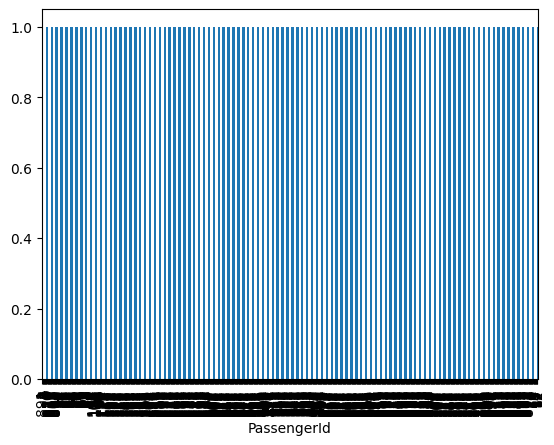

In [116]:
df["PassengerId"].value_counts().plot.bar()

<Axes: xlabel='Ticket'>

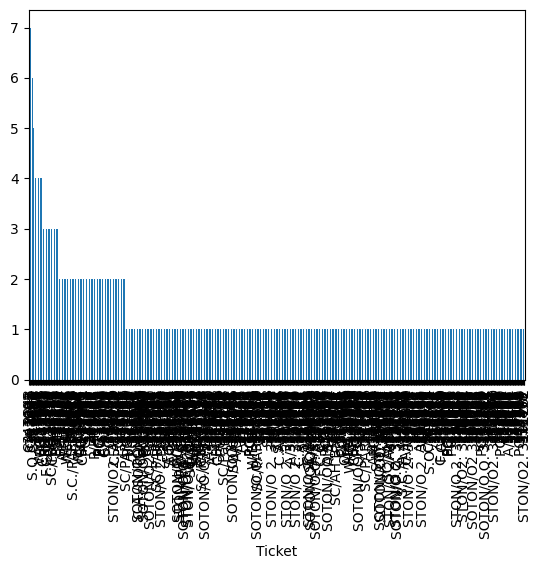

In [117]:
df["Ticket"].value_counts().plot.bar()

In [118]:
del df["PassengerId"] # identificador - distribución uniforme
del df["Ticket"] # la mayoría son valores unicos
del df["Cabin"] # muchos nulos

In [119]:
title = []
for row in df["Name"]:
    pattern = r", ([A-Za-z ]+\.).*"
    title.append(re.search(pattern, row).group(1))

df["Title"] = title

del df["Name"]

In [120]:
df.head(5)

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title
0,0,3,male,22.0,1,0,7.2500,S,Mr.
1,1,1,female,38.0,1,0,71.2833,C,Mrs.
2,1,3,female,26.0,0,0,7.9250,S,Miss.
3,1,1,female,35.0,1,0,53.1000,S,Mrs.
4,0,3,male,35.0,0,0,8.0500,S,Mr.


In [121]:
X = df.drop("Survived", axis=1)
y = df["Survived"]

In [122]:
age_media = X["Age"].mean()
X["Age"] = X["Age"].fillna(age_media)

embarked_moda = X["Embarked"].mode().iloc[0]
X["Embarked"] = X["Embarked"].fillna(embarked_moda)

In [123]:
X.isna().sum()

,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0
Embarked,0
Title,0


In [124]:
X["Family_size"] = X["SibSp"] + X["Parch"] + 1
X["Alone"] = (X["Family_size"] == 1).astype(int)
X["Free_ticket"] = (X["Fare"] == 0.0).astype(int)

In [125]:
X.head(5)

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,Family_size,Alone,Free_ticket
0,3,male,22.0,1,0,7.2500,S,Mr.,2,0,0
1,1,female,38.0,1,0,71.2833,C,Mrs.,2,0,0
2,3,female,26.0,0,0,7.9250,S,Miss.,1,1,0
3,1,female,35.0,1,0,53.1000,S,Mrs.,2,0,0
4,3,male,35.0,0,0,8.0500,S,Mr.,1,1,0


In [126]:
X.shape

(891, 11)

In [127]:
for column in ["Title", "Pclass", "Embarked", "Sex"]:
    encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
    encoder.fit(X[[column]])

    X = pd.concat([
        X.drop(column, axis=1),
        pd.DataFrame(
            encoder.transform(X[[column]]),
            columns=map(lambda x: column + "_" + str(x), encoder.categories_[0])
        )], axis=1
    )

In [128]:
for numeric_column in ["Age", "SibSp", "Parch", "Fare", "Family_size"]:
    scaler = RobustScaler()
    scaler.fit(X[[numeric_column]])

    X[numeric_column] = scaler.transform(X[[numeric_column]])

In [129]:
X.head(5)

,Age,SibSp,Parch,Fare,Family_size,Alone,Free_ticket,Title_Capt.,Title_Col.,Title_Don.,...,Title_Sir.,Title_the Countess.,Pclass_1,Pclass_2,Pclass_3,Embarked_C,Embarked_Q,Embarked_S,Sex_female,Sex_male
0,-0.592240,1.0,0.0,-0.312011,1.0,0,0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
1,0.638529,1.0,0.0,2.461242,1.0,0,0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,-0.284548,0.0,0.0,-0.282777,0.0,1,0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
3,0.407760,1.0,0.0,1.673732,1.0,0,0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
4,0.407760,0.0,0.0,-0.277363,0.0,1,0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0


In [130]:
X.describe()

,Age,SibSp,Parch,Fare,Family_size,Alone,Free_ticket,Title_Capt.,Title_Col.,Title_Don.,...,Title_Sir.,Title_the Countess.,Pclass_1,Pclass_2,Pclass_3,Embarked_C,Embarked_Q,Embarked_S,Sex_female,Sex_male
count,8.910000e+02,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,...,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,2.153160e-16,0.523008,0.381594,0.768745,0.904602,0.602694,0.016835,0.001122,0.002245,0.001122,...,0.001122,0.001122,0.242424,0.206510,0.551066,0.188552,0.086420,0.725028,0.352413,0.647587
std,1.000155e+00,1.102743,0.806057,2.152200,1.613459,0.489615,0.128725,0.033501,0.047351,0.033501,...,0.033501,0.033501,0.428790,0.405028,0.497665,0.391372,0.281141,0.446751,0.477990,0.477990
min,-2.252240e+00,0.000000,0.000000,-0.626005,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,-5.922398e-01,0.000000,0.000000,-0.283409,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000e+00,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,1.000000
75%,4.077602e-01,1.000000,0.000000,0.716591,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000
max,3.869299e+00,8.000000,6.000000,21.562738,10.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [131]:
X.shape

(891, 32)

In [132]:
X.columns

Index(['Age', 'SibSp', 'Parch', 'Fare', 'Family_size', 'Alone', 'Free_ticket',
       'Title_Capt.', 'Title_Col.', 'Title_Don.', 'Title_Dr.',
       'Title_Jonkheer.', 'Title_Lady.', 'Title_Major.', 'Title_Master.',
       'Title_Miss.', 'Title_Mlle.', 'Title_Mme.', 'Title_Mr.', 'Title_Mrs.',
       'Title_Ms.', 'Title_Rev.', 'Title_Sir.', 'Title_the Countess.',
       'Pclass_1', 'Pclass_2', 'Pclass_3', 'Embarked_C', 'Embarked_Q',
       'Embarked_S', 'Sex_female', 'Sex_male'],
      dtype='object')

In [133]:
# Configurar modelo
k_vecinos = 13 #29
knn = KNeighborsClassifier(n_neighbors=k_vecinos)

In [134]:
variables_grafica = ["Age", "Fare", "SibSp", "Parch", "Family_size"]

#parejas de variables
parejas = []
for i in range(len(variables_grafica)):
    for j in range(i + 1, len(variables_grafica)):
        parejas.append((variables_grafica[i], variables_grafica[j]))

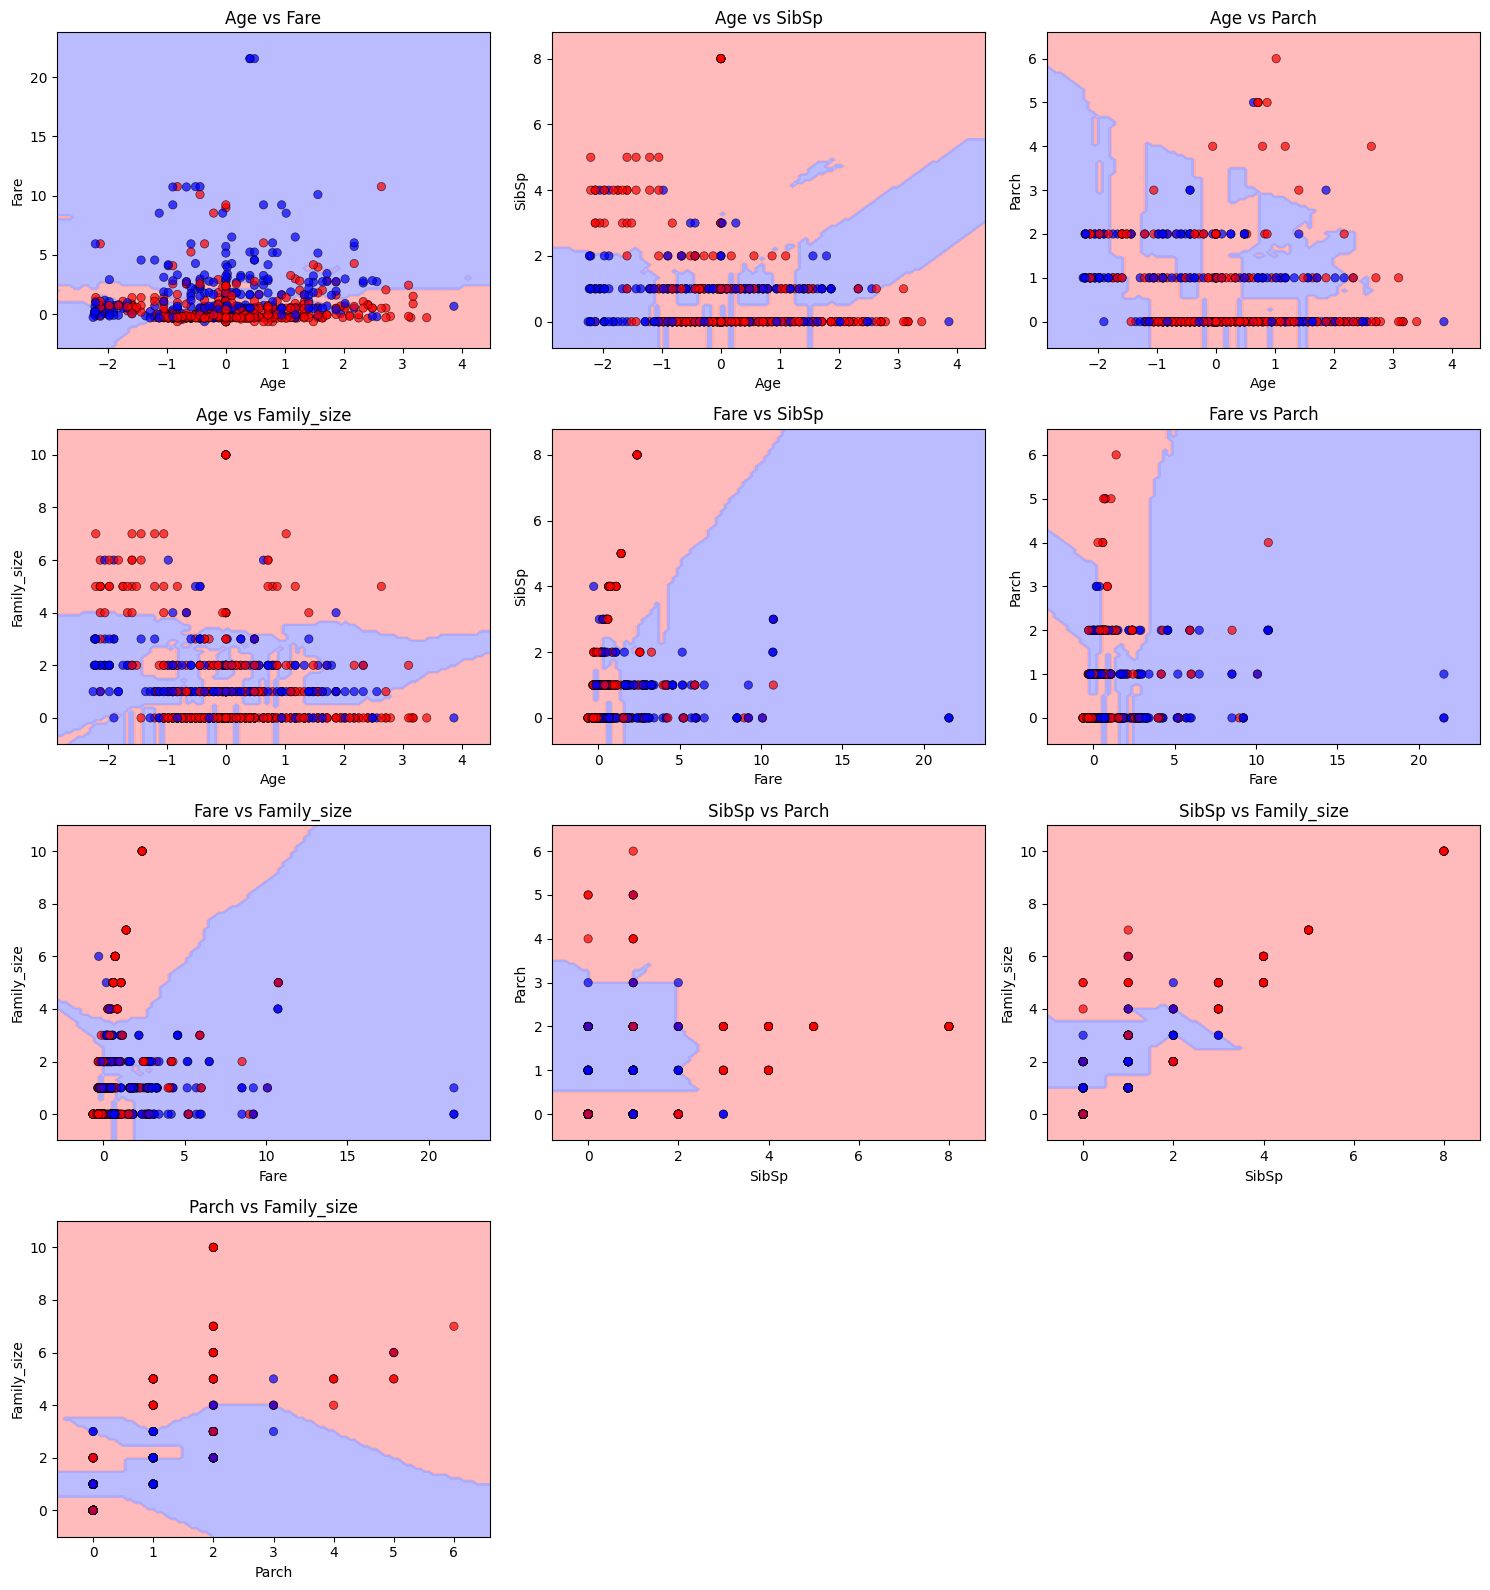

In [135]:
num_plots = len(parejas)
cols = 3
rows = (num_plots + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows))
axes = axes.flatten()

cmap_light = ListedColormap(['#FFAAAA', '#AAAAFF'])
cmap_bold = ['red', 'blue']

for i in range(num_plots):
    var1, var2 = parejas[i]
    ax = axes[i]

    X_subset = X[[var1, var2]].values
    y_subset = y.values

    # Entrenamiento
    knn.fit(X_subset, y_subset)

    margen_x = (X_subset[:, 0].max() - X_subset[:, 0].min()) * 0.1
    margen_y = (X_subset[:, 1].max() - X_subset[:, 1].min()) * 0.1

    x_min, x_max = X_subset[:, 0].min() - margen_x, X_subset[:, 0].max() + margen_x
    y_min, y_max = X_subset[:, 1].min() - margen_y, X_subset[:, 1].max() + margen_y

    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100),
                         np.linspace(y_min, y_max, 100))

    Z = knn.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    ax.contourf(xx, yy, Z, cmap=cmap_light, alpha=0.8)
    sns.scatterplot(x=X_subset[:, 0], y=X_subset[:, 1], hue=y_subset,
                    palette=cmap_bold, edgecolor="black", alpha=0.7, ax=ax, legend=False)

    ax.set_title(f"{var1} vs {var2}")
    ax.set_xlabel(var1)
    ax.set_ylabel(var2)

for j in range(num_plots, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Como se puede observar en las gráficas, no se pueden clasificar bien los datos entre sobrevivió o no sobrevivió, por lo que con una pareja de variables por sí sola no es sufieciente para separar perfectamente a los sobrevivientes de las victimas

---

Ahora realizaremos combinaciones entre las variables categóricas que fueron codificadas: Pclass y Sex para ver cómo interactuan para separar a los sobrevivientes y las victimas

Dado que todos los puntos reales del dataset van a caer exactamente en las coordenadas (0,0), (0,1), (1,0) o (1,1) por la codificación utilizaremos jitter para que no se vea solo un punto

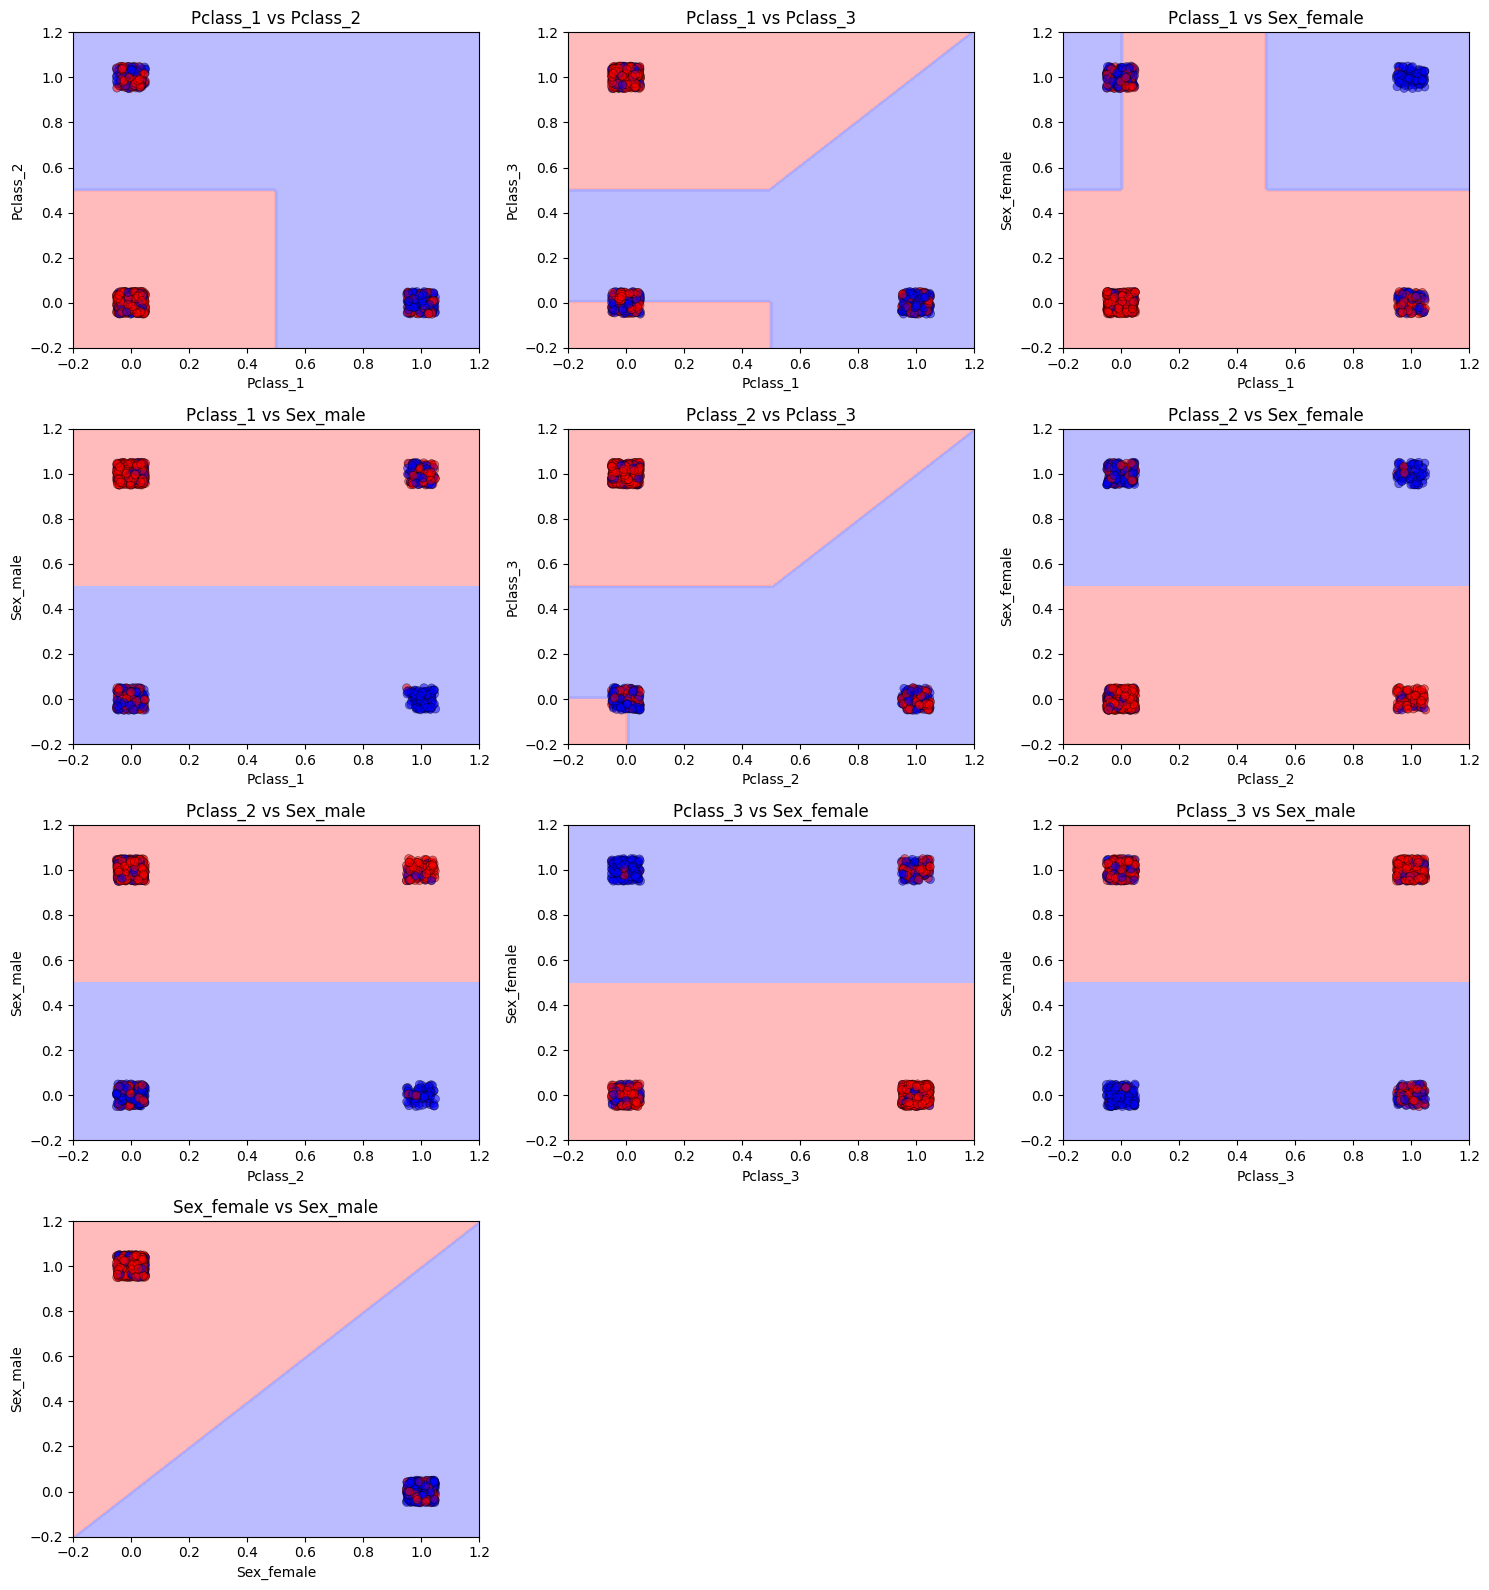

In [136]:
variables_grafica_cat = ["Pclass_1", "Pclass_2", "Pclass_3", "Sex_female", "Sex_male"]

variables_grafica_cat = [v for v in variables_grafica_cat if v in X.columns]

parejas_cat = []
for i in range(len(variables_grafica_cat)):
    for j in range(i + 1, len(variables_grafica_cat)):
        parejas_cat.append((variables_grafica_cat[i], variables_grafica_cat[j]))

num_plots_cat = len(parejas_cat)
cols_cat = 3
rows_cat = (num_plots_cat + cols_cat - 1) // cols_cat

fig, axes = plt.subplots(rows_cat, cols_cat, figsize=(5 * cols_cat, 4 * rows_cat))
axes = axes.flatten()

cmap_light = ListedColormap(['#FFAAAA', '#AAAAFF'])
cmap_bold = ['red', 'blue']

for i in range(num_plots_cat):
    var1, var2 = parejas_cat[i]
    ax = axes[i]

    X_subset = X[[var1, var2]].values
    y_subset = y.values

    # Entrenamiento
    knn.fit(X_subset, y_subset)

    x_min, x_max = -0.2, 1.2
    y_min, y_max = -0.2, 1.2

    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100),
                         np.linspace(y_min, y_max, 100))

    Z = knn.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    ax.contourf(xx, yy, Z, cmap=cmap_light, alpha=0.8)

    jitter_x = np.random.uniform(-0.05, 0.05, size=len(X_subset[:, 0]))
    jitter_y = np.random.uniform(-0.05, 0.05, size=len(X_subset[:, 1]))

    sns.scatterplot(x=X_subset[:, 0] + jitter_x, y=X_subset[:, 1] + jitter_y, hue=y_subset,
                    palette=cmap_bold, edgecolor="black", alpha=0.5, ax=ax, legend=False)

    ax.set_title(f"{var1} vs {var2}")
    ax.set_xlabel(var1)
    ax.set_ylabel(var2)
    ax.set_xlim(-0.2, 1.2)
    ax.set_ylim(-0.2, 1.2)

for j in range(num_plots_cat, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Observamos que, al codificar las variables, los puntos se encuentran en las esquinas del gráfico y las fronteras son lineas no curvas, aún así tampoco se logra ver una seáración perfecta